In [12]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize

In [2]:
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

In [5]:
sigma_values = np.linspace(1, 2, 4)
threshold = 0.35
blob_responses = []
for sigma in sigma_values:
    print(f"Processing scale with sigma = {sigma}")
    gaussian_blur = cv.GaussianBlur(gray, (0, 0), sigma)
    laplacian = cv.Laplacian(gaussian_blur, cv.CV_64F)
    blob_response = np.abs(laplacian)
    mask = blob_response > threshold * blob_response.max()
    contours, _ = cv.findContours(mask.astype(np.uint8), cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    for contour in contours:
        if len(contour) >= 5:
            (center_x, center_y), radius = cv.minEnclosingCircle(contour)
            center = (int(center_x), int(center_y))
            radius = int(radius)
            blob_responses.append((center, radius, sigma))

Processing scale with sigma = 1.0
Processing scale with sigma = 1.3333333333333333
Processing scale with sigma = 1.6666666666666665
Processing scale with sigma = 2.0


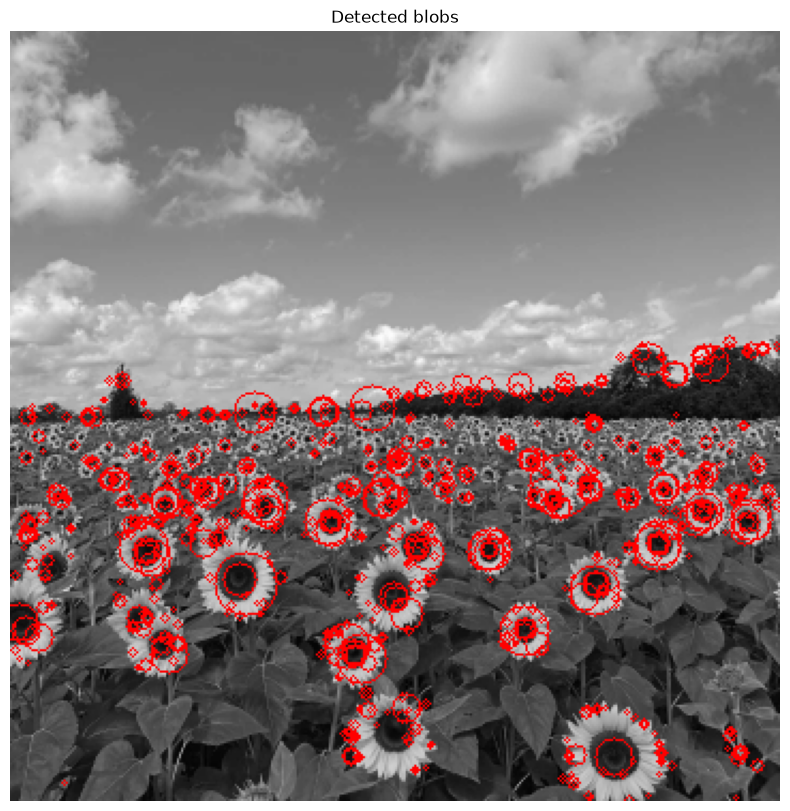

In [6]:
output = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)
for blob in blob_responses:
    center, radius, _ = blob
    cv.circle(output, center, radius, (0, 0, 255), 1)
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB), cmap='gray')
plt.axis('off')
plt.title('Detected blobs')
plt.show()

In [7]:
blobs_sorted = sorted(blob_responses, key=lambda x: x[1], reverse=True)
largest_blob = blobs_sorted[0]
center, radius, sigma = largest_blob
print(f"Largest blob at : {center} with radius {radius} and sigma {sigma}")

Largest blob at : (110, 258) with radius 15 and sigma 2.0


0.71,1.41,2.12,2.83,3.54,4.24,4.95,5.66,6.36,7.07,

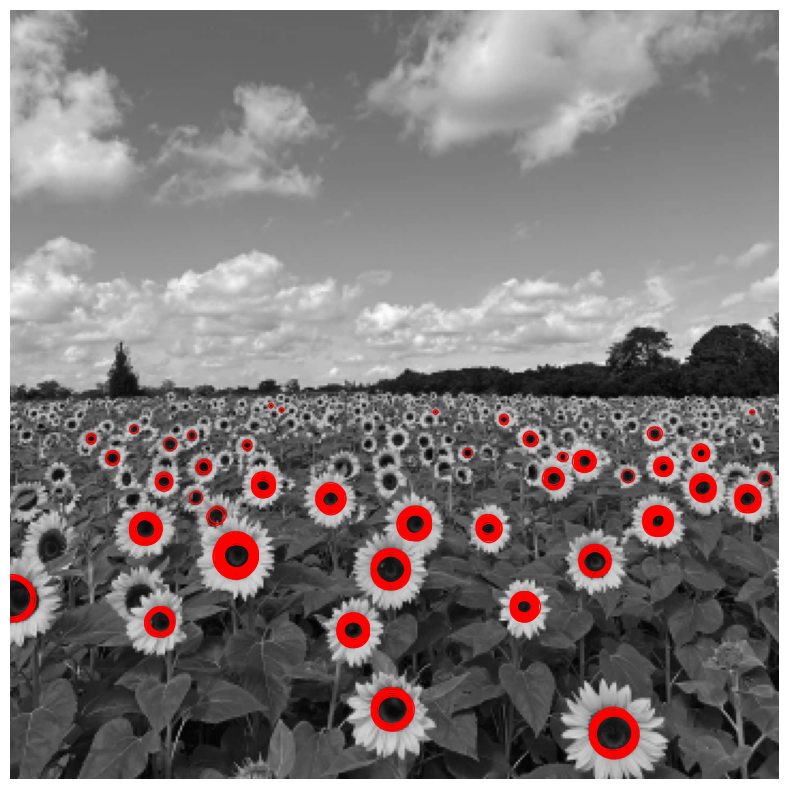

In [8]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the image and convert it to grayscale
img1 = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(img1, cv.COLOR_BGR2GRAY) / 255

# Display the grayscale image with detected circles
plt.figure(figsize=(10, 10), frameon=False)
plt.imshow(gray, cmap='gray')
plt.axis('off')

# Get the current axes object
ax = plt.gca()

patches = []
labels = []

# Detect blobs at different sigma values
for r in range(1, 11):
    sigma = r / 1.414
    print(f"{sigma:.2f}", end=",")
    hw = round(3 * sigma)  # Half width of the kernel
    X, Y = np.meshgrid(np.arange(-hw, hw + 1, 1), np.arange(-hw, hw + 1, 1))

    # Calculate Laplacian of Gaussian (LoG) filter
    LOG = ((X**2 + Y**2) / (2 * sigma**2) - 1) * np.exp(-(X**2 + Y**2) / (2 * sigma**2)) / (np.pi * sigma**4)
    
    # Scale the filter and apply it to the image
    LOG = sigma**2 * LOG
    img1_log = np.square(cv.filter2D(gray, -1, LOG))

    # Detect maxima manually
    coordinates = []
    (H, W) = img1_log.shape
    k = 1  # Neighborhood size
    threshold = 0.1  # Threshold for maxima detection
    for i in range(k, H - k):
        for j in range(k, W - k):
            slice_img = img1_log[i - k:i + k + 1, j - k:j + k + 1]
            if np.max(slice_img) >= threshold:
                # Get coordinates of the maximum point
                x, y = np.unravel_index(slice_img.argmax(), slice_img.shape)
                coordinates.append((i + x - k, j + y - k))
    coordinates = set(coordinates)

    # Plot circles around detected blobs
    for x, y in coordinates:
        c = plt.Circle((y, x), sigma * 1.414, color='r', linewidth=1, fill=False)
        ax.add_patch(c)
    patches.append(c)
    ax.plot()

ax.set_xlim([0, img1.shape[1]])
ax.set_ylim([img1.shape[0], 0])

# Add legend and title
plt.axis('off')
plt.show()


Question 2

In [9]:
np.random.seed(0)
N = 100
half_n = N//2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
X = np.vstack((X_circ, X_line))  

In [10]:
def line_distance(params, X):
    a, b, d = params
    return np.abs(a * X[:, 0] + b * X[:, 1] + d)

def ransac_line(X, num_iterations=1000, threshold=1.4, min_inliers=35):
    best_inliers = []
    best_params = None

    for _ in range(num_iterations):
        sample_idx = np.random.choice(len(X), 2, replace=False)
        p1, p2 = X[sample_idx]
        a = p2[1] - p1[1]
        b = p1[0] - p2[0]
        d = -(a * p1[0] + b * p1[1])
        norm = np.sqrt(a**2 + b**2)
        a, b, d = a / norm, b / norm, d / norm

        distances = line_distance([a, b, d], X)
        inliers = np.where(distances < threshold)[0]
        if len(inliers) > len(best_inliers) and len(inliers) >= min_inliers:
            best_inliers = inliers
            best_params = [a, b, d]
            best_sample = X[sample_idx]

    return best_params, best_inliers, best_sample

sample_line_params, line_idx, line_sample = ransac_line(X)
line_inliers = X[line_idx]
center = line_inliers.mean(axis=0)
_, _, Vt = np.linalg.svd(line_inliers - center)
a, b = Vt[-1]
d = -np.dot([a, b], center)
best_line_params = [a, b, d]

remaining_points = np.delete(X, line_idx, axis=0)
print('Line parameters:', best_line_params)
print('Line inliers:', len(line_inliers))

Line parameters: [np.float64(-0.7209645896651433), np.float64(-0.6929719045163169), np.float64(1.572415162927794)]
Line inliers: 54


In [13]:
def circle_distance(params, X):
    x0, y0, r = params
    return np.abs(np.sqrt((X[:, 0] - x0)**2 + (X[:, 1] - y0)**2) - r)

def ransac_circle(X, num_iterations=1000, threshold=1.5, min_inliers=25):
    best_inliers = []
    best_params = None

    for _ in range(num_iterations):
        sample_idx = np.random.choice(len(X), 3, replace=False)
        p1, p2, p3 = X[sample_idx]
        A = np.array([[p1[0], p1[1], 1],
                      [p2[0], p2[1], 1],
                      [p3[0], p3[1], 1]])
        B = -np.sum(X[sample_idx]**2, axis=1)
        if abs(np.linalg.det(A)) < 1e-8:
            continue
        C = np.linalg.solve(A, B)
        x0, y0 = -0.5 * C[0], -0.5 * C[1]
        r = np.sqrt(x0**2 + y0**2 - C[2])

        distances = circle_distance([x0, y0, r], X)
        inliers = np.where(distances < threshold)[0]
        if len(inliers) > len(best_inliers) and len(inliers) >= min_inliers:
            best_inliers = inliers
            best_params = [x0, y0, r]
            best_sample = X[sample_idx]

    return best_params, best_inliers, best_sample

sample_circle_params, circle_idx, circle_sample = ransac_circle(remaining_points)
circle_inliers = remaining_points[circle_idx]

result = minimize(lambda params: np.sum(circle_distance(params, circle_inliers)**2),
                  sample_circle_params)
best_circle_params = result.x
print('Circle parameters:', best_circle_params)
print('Circle inliers:', len(circle_inliers))

Circle parameters: [1.94939851 2.98785108 9.89192183]
Circle inliers: 46


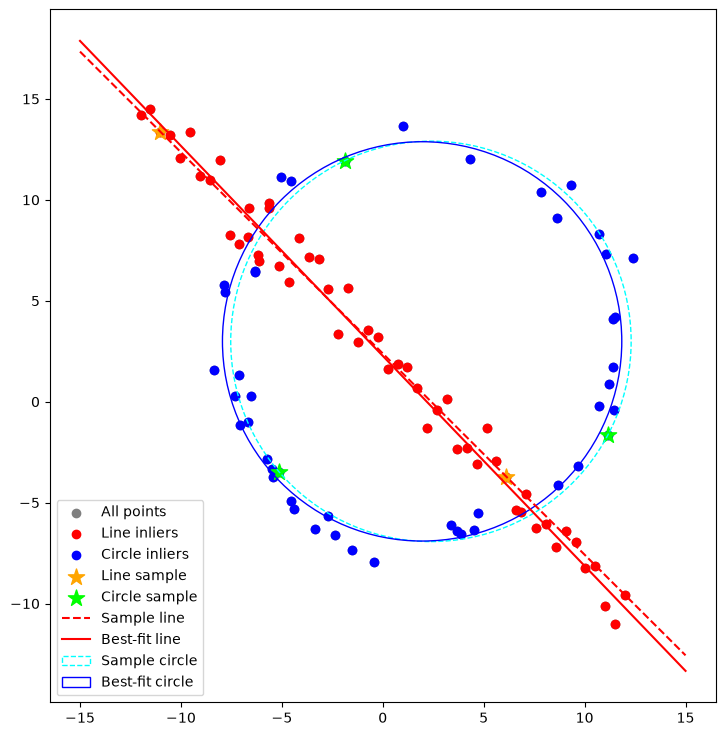

In [14]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(X[:, 0], X[:, 1], color='gray', label='All points')
ax.scatter(line_inliers[:, 0], line_inliers[:, 1], color='red', label='Line inliers')
ax.scatter(circle_inliers[:, 0], circle_inliers[:, 1], color='blue', label='Circle inliers')
ax.scatter(line_sample[:, 0], line_sample[:, 1], s=150, marker='*', color='orange', label='Line sample')
ax.scatter(circle_sample[:, 0], circle_sample[:, 1], s=150, marker='*', color='lime', label='Circle sample')

x_vals = np.array([-15, 15])
a, b, d = sample_line_params
ax.plot(x_vals, -(a * x_vals + d) / b, 'r--', label='Sample line')
a, b, d = best_line_params
ax.plot(x_vals, -(a * x_vals + d) / b, 'r-', label='Best-fit line')

x0, y0, r = sample_circle_params
ax.add_patch(plt.Circle((x0, y0), r, color='cyan', linestyle='--', fill=False, label='Sample circle'))
x0, y0, r = best_circle_params
ax.add_patch(plt.Circle((x0, y0), r, color='blue', fill=False, label='Best-fit circle'))
ax.set_aspect('equal')
ax.legend()
plt.show()